# 1. Problem and real acquisition
Recover the three-dimensional centers, radii and refractive indices of two colloidal spheres suspended in water from a real holographic flow-metrology frame. An independently acquired particle-free frame calibrates spatial illumination. Native camera counts are preserved. The nominal author-provided dark offset is13counts; no independent dark frame or particle-property truth is available. Holographic particle characterization supports flow cytometry and colloidal transport measurements.

### Data and coordinate units
Pixel coordinates x increase rightward and y downward from the full frame upper-left origin. The camera is at z=0; positive particle z points above that plane and incident light propagates in the negative-z direction. The incident electric field is polarized along x. Vacuum wavelength is0.447micrometre, object-space pixel spacing0.048micrometre/pixel and water refractive index1.34. ROIs retain full-frame coordinates.

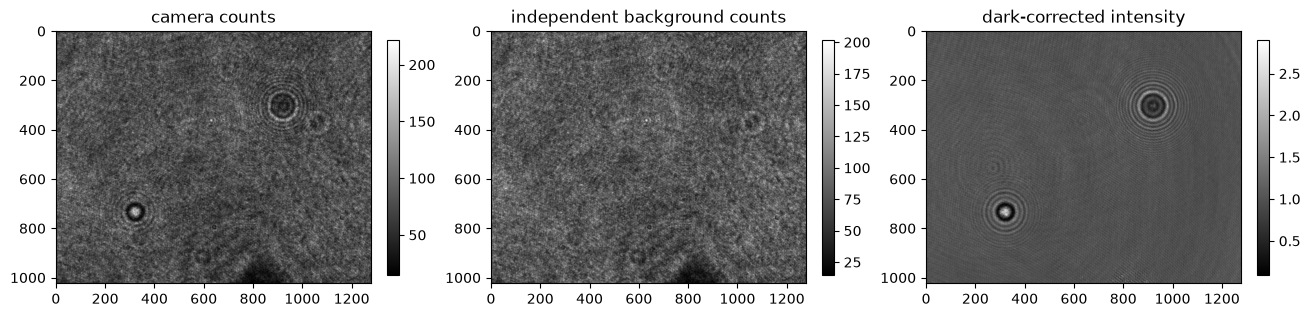

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load,regions
from src.solvers import reconstruct,model_at
from src.visualization import comparison
image,background,observed=load()
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,a,title in zip(axs,[image,background,observed],['camera counts','independent background counts','dark-corrected intensity']):
 im=ax.imshow(a,cmap='gray');ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.6)
plt.show()

# 2. Forward physics and conditional target
Let I and B be sample and independent background camera counts, d=13counts the nominal dark offset and J the dimensionless measured hologram. Let a be sphere radius in micrometres, lambda the vacuum wavelength in micrometres, nm the water index and np the real particle index. The homogeneous, nonabsorbing sphere has relative index m and size parameter chi:

$$J=\frac{I-d}{B-d},\qquad k=\frac{2\pi n_m}{\lambda},\qquad \chi=ka,\qquad m=\frac{n_p}{n_m}.$$

Here k has units inverse micrometre. Pixel positions are converted to physical displacements using the known pixel spacing. At a camera location r, the normalized vector scattered electric field Es(r;q) is the outgoing Lorenz-Mie solution for the sphere q=(x,y,z,a,np), including its incident phase. With ex the unit vector in the polarization direction, the predicted dimensionless intensity is

$$H(\mathbf r;\mathbf q)=\left\|\mathbf e_x+\mathbf E_s(\mathbf r;\mathbf q)\right\|_2^2.$$

The forward model evaluates the sphere electric/magnetic multipole coefficients and their vector spherical-wave recurrence explicitly. There is no fitted background, amplitude or neighbor correction. The incident field has unit amplitude after normalization. The library's Bohren/outgoing-wave convention and the incident exp(-ikz) phase are retained consistently with negative-z illumination.

Each ROI is a separate isolated-sphere conditional problem. Its valid set V contains every observed pixel except pixels attaining that ROI's maximum J; this is an observed-maximum exclusion convention, with no verified camera-saturation claim. The public robust objective is

$$C(\mathbf q)=\frac{1}{|V|}\sum_{j\in V}\log\!\left[1+\left(\frac{H_j(\mathbf q)-J_j}{s}\right)^2\right],\qquad s=0.05.$$

The dimensionless robust scale s is a modeling choice, not a measured photon-noise deviation. All five unknowns enter H jointly. Finite resolution, fringes from neighbors and radius/index/depth tradeoffs allow multiple good conditional solutions. Forward agreement and objective quality are evaluated separately from parameter identity.


In [2]:
with np.load('test/fixtures/upstream_forward.npz') as f:
 err=np.max(np.abs(model_at(f['param_particle'],f['input_coordinates'])-f['output_hologram']))
print('Independent upstream forward maximum error:',err)
assert err<2e-11

Independent upstream forward maximum error: 0.0


# 3. Method and active reconstruction
Global initialization explores fringe-order ambiguities. Local Cauchy refinement uses every declared valid pixel and enforces the physical bounds. Numerical seeds are maintainer reproducibility choices. The source tutorial changed height-bound units without updating the example; the corrected4.8–16.8micrometre bounds correspond to100–350pixels at0.048micrometre/pixel. This unit adaptation is documented separately from unchanged scattering mathematics.

Fresh local parameters x,y,z[px],radius[um],index: [[[9.20963433e+02 3.03379652e+02 2.16481037e+02 1.21406868e+00
   1.71027604e+00]
  [3.21764118e+02 7.33422826e+02 2.31743166e+02 8.80912451e-01
   1.44490727e+00]]]
Active runtime seconds: 16.124573499895632 diagnostics: [{'cost': 1.224126635862471, 'nfev': 14, 'success': True}, {'cost': 1.1602397172224104, 'nfev': 9, 'success': True}]


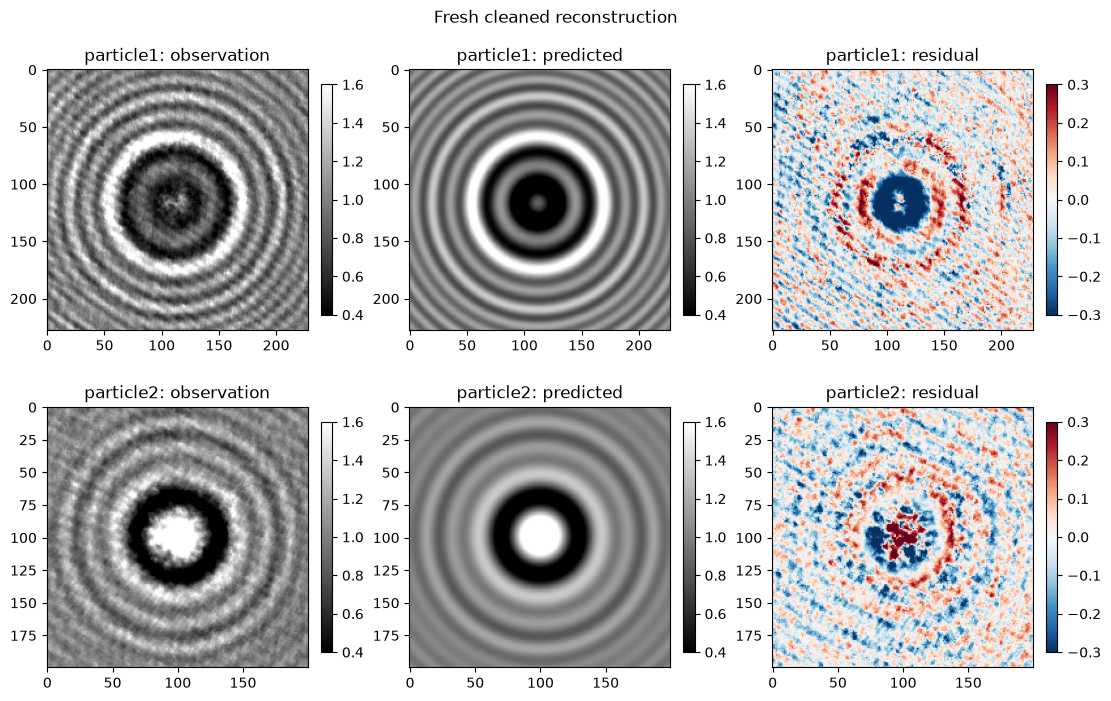

In [3]:
t=time.perf_counter();fresh,diagnostics=reconstruct(observed);elapsed=time.perf_counter()-t
np.savez('output/reconstruction.npz',reconstruction=fresh)
print('Fresh local parameters x,y,z[px],radius[um],index:',fresh)
print('Active runtime seconds:',elapsed,'diagnostics:',diagnostics)
comparison(observed,fresh,'Fresh cleaned reconstruction');plt.show()

# 4. Independent upstream comparison
The archived reference is the actual full-mask upstream robust fit on these exact observations, not a historical paper value. The source tutorial documentation has an inconsistent height-bound unit; validation.md records the failed literal example and the independently checked unit adaptation. Agreement of forward calculations is tested; parameter identity is scientifically unnecessary. Different radii and indices can yield a lower robust residual for the first sphere.

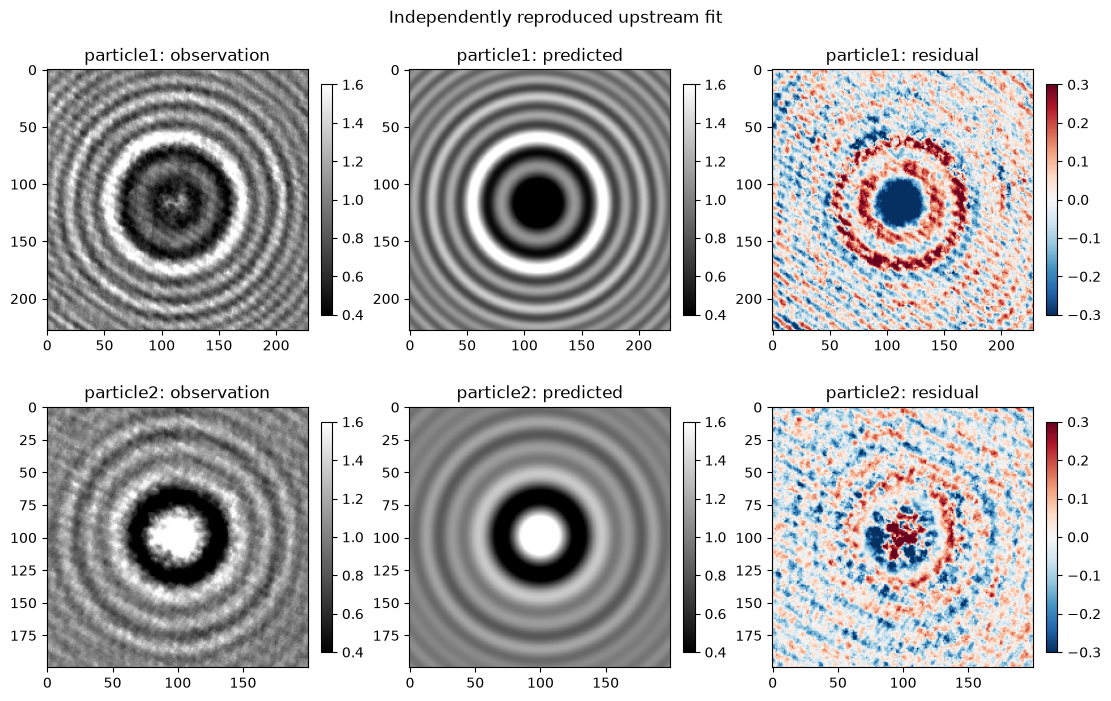

| Particle | Method | x (pixel) | y (pixel) | z (pixel) | Radius (micrometre) | Refractive index (1) |
|---|---|---:|---:|---:|---:|---:|
| 1 | reproduced source | 920.89326 | 303.42197 | 226.93692 | 1.0643718 | 1.5669531 |
| 1 | fresh local | 920.96343 | 303.37965 | 216.48104 | 1.2140687 | 1.710276 |
| 2 | reproduced source | 321.76451 | 733.42326 | 231.7351 | 0.88096263 | 1.4448162 |
| 2 | fresh local | 321.76412 | 733.42283 | 231.74317 | 0.88091245 | 1.4449073 |

In [4]:
with np.load('notebooks/reference_outputs/upstream_fit.npz') as f:upstream=f['reconstruction']
comparison(observed,upstream,'Independently reproduced upstream fit');plt.show()
from IPython.display import display,Markdown
rows=['| Particle | Method | x (pixel) | y (pixel) | z (pixel) | Radius (micrometre) | Refractive index (1) |','|---|---|---:|---:|---:|---:|---:|']
for i in range(2):
 for name,q in [('reproduced source',upstream),('fresh local',fresh)]:
  rows.append('| '+str(i+1)+' | '+name+' | '+' | '.join(f'{v:.8g}' for v in q[0,i])+' |')
display(Markdown('\n'.join(rows)))


# 5. Ablations and robustness
Each comparison is actually computed with local equations. Linear loss tests outlier sensitivity; omitting global exploration tests local initialization; an independently drawn0.01dimensionless Gaussian perturbation tests sensitivity to observation changes. Perturbation is a diagnostic only and is never substituted for the bound data.

{'fresh Cauchy': [1.224126635862471, 1.1602397172224104], 'upstream Cauchy': [1.3408371701343458, 1.1602416266942688], 'linear loss': [1.226856800421031, 1.172130726437846], 'local initialization': [1.340562219193537, 1.1602397172416952], 'added noise': [1.3405722457929892, 1.1602493416062516]}


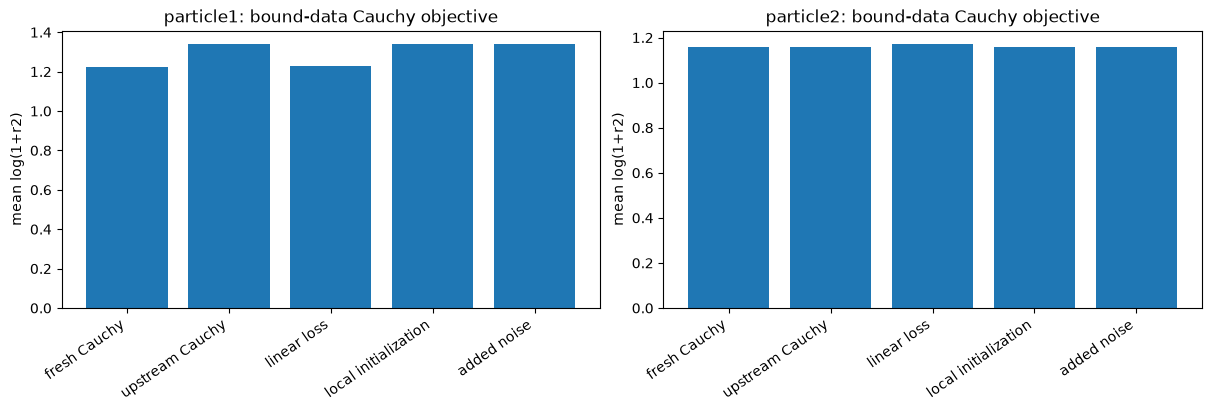

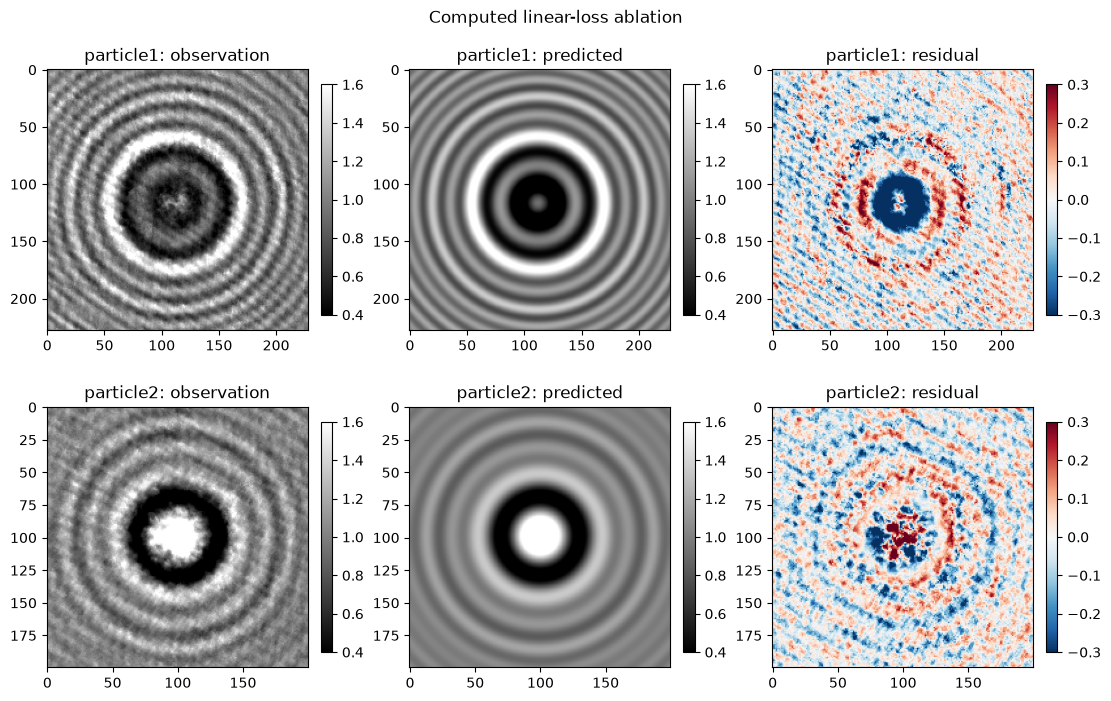

In [5]:
variants={'fresh Cauchy':fresh,'upstream Cauchy':upstream}
for name,opts in [('linear loss',dict(robust=False)),('local initialization',dict(global_search=False))]:
 variants[name],_=reconstruct(observed,**opts)
rng=np.random.default_rng(64);perturbed=observed+rng.normal(0,.01,observed.shape)
variants['added noise'],_=reconstruct(perturbed)
def costs(q):
 values=[]
 for i,(crop,c,v) in enumerate(regions(observed)):
  r=(model_at(q[0,i],c[:,v])-crop.ravel()[v])/.05;values.append(np.log1p(r*r).mean())
 return values
table=np.array([costs(q) for q in variants.values()]);print(dict(zip(variants,table.tolist())))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for i,ax in enumerate(axes):ax.bar(np.arange(len(table)),table[:,i]);ax.set_xticks(np.arange(len(table)),list(variants),rotation=35,ha='right');ax.set_title(f'particle{i+1}: bound-data Cauchy objective');ax.set_ylabel('mean log(1+r2)')
plt.show()
comparison(observed,variants['linear loss'],'Computed linear-loss ablation');plt.show()

# 6. Evaluation and limitations
Standalone evaluation checks shape, dtype, finite values, physical bounds and both robust observation objectives. It accepts better conditional fits instead of forcing parameters to match a finite nonconvex run. Model mismatch, neighbors and finite camera resolution preclude claiming independent physical truth. The two ROI fits are conditional isolated-sphere descriptions, not a coherent multiple-scattering fit of the entire suspension. All observations, calibration, objective scale and bounds are public.

In [6]:
import subprocess
p=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding="utf-8")
print(Path('output/judge_report.json').read_text(encoding="utf-8"));assert p.returncode==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "particle_1_cauchy": 1.224126635862471,
    "particle_2_cauchy": 1.1602397172224104
  },
  "thresholds": {
    "particle_1_cauchy": {
      "comparison": "<=",
      "boundary": 1.342
    },
    "particle_2_cauchy": {
      "comparison": "<=",
      "boundary": 1.161
    }
  },
  "errors": []
}
